In [3]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.cleaning import load_processed
from src.metrics import add_core_metrics, add_rolling_metrics, add_strain_relief
from src.compare import compare_periods, early_late_periods, yearly_periods

pd.options.display.float_format = "{:,.1f}".format
df = add_strain_relief(add_rolling_metrics(add_core_metrics(load_processed())))
rep = df[df["is_reported"]]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
print(early_late_periods(df))
compare_periods(df, early_late_periods(df))

{'early': (Timestamp('2023-01-12 00:00:00'), Timestamp('2024-07-02 00:00:00')), 'late': (Timestamp('2024-07-03 00:00:00'), Timestamp('2025-12-21 00:00:00'))}


,early,late
reports,359.0,361.0
avg_total_load,"8,615.3","3,863.5"
peak_total_load,"11,762.0","7,016.0"
avg_cbp_custody,239.4,104.0
avg_hhs_care,"8,375.9","3,759.4"
cbp_share_pct,2.8,2.7
avg_apprehended,132.6,54.7
avg_transferred,184.2,73.5
avg_discharged,272.5,74.9
avg_net_intake,-88.3,-1.4


In [5]:
compare_periods(df, yearly_periods(df))

,2023,2024,2025
reports,230.0,251.0,239.0
avg_total_load,"8,846.5","7,319.9","2,575.7"
peak_total_load,"11,762.0","10,994.0","6,471.0"
avg_cbp_custody,200.5,276.9,32.9
avg_hhs_care,"8,646.1","7,043.0","2,542.8"
cbp_share_pct,2.3,3.8,1.3
avg_apprehended,117.6,148.1,13.0
avg_transferred,157.1,209.4,16.6
avg_discharged,288.0,205.9,29.0
avg_net_intake,-131.0,3.4,-12.4


In [6]:
c = rep["cbp_custody"].astype(float)
h = rep["hhs_care"].astype(float)

share = c / (c + h) * 100
print("CBP share of total (%): mean", round(share.mean(), 2),
      " median", round(share.median(), 2), " max", round(share.max(), 2))
print("correlation CBP vs HHS:", round(c.corr(h), 3))
print("peak dates  CBP:", c.idxmax().date(), " HHS:", h.idxmax().date())
print("swing (std/mean, %) CBP:", (c.groupby(rep.index.year).std() / c.groupby(rep.index.year).mean() * 100).round(1).to_dict())
print("swing (std/mean, %) HHS:", (h.groupby(rep.index.year).std() / h.groupby(rep.index.year).mean() * 100).round(1).to_dict())

CBP share of total (%): mean 2.47  median 2.36  max 6.36
correlation CBP vs HHS: 0.664
peak dates  CBP: 2024-02-04  HHS: 2023-12-20
swing (std/mean, %) CBP: {2023: 42.8, 2024: 32.9, 2025: 73.0}
swing (std/mean, %) HHS: {2023: 18.4, 2024: 15.2, 2025: 33.1}


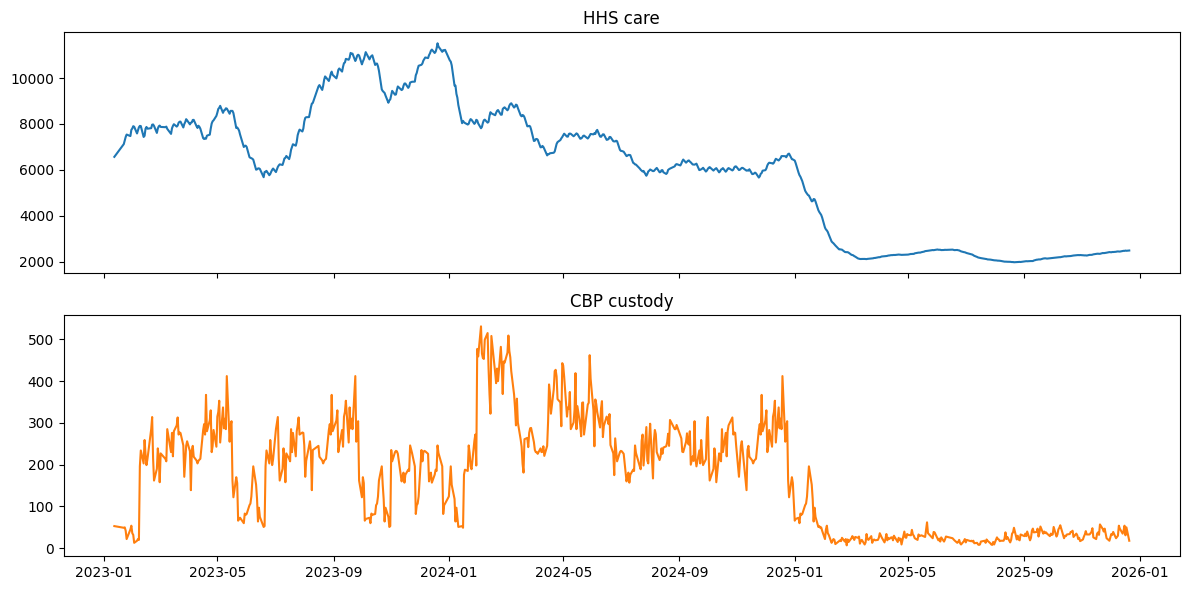

In [7]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
a1.plot(rep.index, h)
a1.set_title("HHS care")
a2.plot(rep.index, c, color="tab:orange")
a2.set_title("CBP custody")
plt.tight_layout()